# Course Recommendation System —


In [ ]:
%pip -q install pandas numpy scikit-learn langdetect matplotlib


## 0. Imports

In [ ]:
from pathlib import Path
import os, re, html, shutil, hashlib, json, warnings
from urllib.parse import urlparse
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj.to_string(index=False) if hasattr(obj, 'to_string') else obj)

import matplotlib.pyplot as plt
from IPython.display import display, Markdown


## 1. Paths and data

In [ ]:

DATASET_FILES = [
    '3.1-data-sheet-udemy-courses-business-courses.csv',
    '3.1-data-sheet-udemy-courses-design-courses.csv',
    '3.1-data-sheet-udemy-courses-music-courses.csv',
    '3.1-data-sheet-udemy-courses-web-development.csv',
    'Udemy.csv', 'udemy_output_All_Business_p1_p626.csv',
    'Coursera.csv', 'coursea_data.csv', 'edx.csv', 'edx_courses.csv',
    'pluralsight.csv', 'skillshare.csv', 'Online_Courses.csv', 'courses.csv',
    'reviews_by_course.csv',
]
try:
    from google.colab import drive, files
    IN_COLAB = True
    drive.mount('/content/drive', force_remount=False)
    DRIVE_ROOT = Path('/content/drive/MyDrive')
    BASE_DIR = DRIVE_ROOT / 'CourseRecommendationSystem'
except ImportError:
    IN_COLAB = False
    DRIVE_ROOT = None
    BASE_DIR = Path.cwd() / 'CourseRecommendationSystem'
DATA_DIR = BASE_DIR / 'data'
OUTPUT_DIR = BASE_DIR / 'outputs'
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if IN_COLAB:
    for name in DATASET_FILES:
        target = DATA_DIR / name
        if not target.exists():
            try:
                found = next((p for p in DRIVE_ROOT.rglob(name) if p.is_file() and DATA_DIR not in p.parents), None)
            except (PermissionError, OSError):
                found = None
            if found:
                shutil.copy2(found, target)
                print(f'Found existing Drive file and copied it: {found} -> {target}')

missing = [name for name in DATASET_FILES if not (DATA_DIR / name).exists()]
if missing:
    print('Files not found in the expected folder (reviews_by_course.csv is optional):')
    for name in missing:
        print(' -', name)
    if IN_COLAB:
        print('Select only the missing files in the upload dialog. Files already in Drive were not requested.')
        uploaded = files.upload()
        for name, content in uploaded.items():
            dest = DATA_DIR / Path(name).name
            dest.write_bytes(content)
            print('Saved:', dest)
    else:
        print('Copy available CSVs into:', DATA_DIR.resolve())
print('\nData folder:', DATA_DIR)
print('Cache/model support folder:', OUTPUT_DIR)
print('Report tables and charts will be displayed in notebook cells; they will not be exported as report files.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Data folder: /content/drive/MyDrive/CourseRecommendationSystem/data
Cache/model support folder: /content/drive/MyDrive/CourseRecommendationSystem/outputs
Report tables and charts will be displayed in notebook cells; they will not be exported as report files.


## --comman schema


In [ ]:
COMMON_COLS = ['course_title','description','category','level','rating','num_reviews','students','price','duration','url','source']
def clean_text(value):
    if pd.isna(value): return ''
    value = html.unescape(str(value))
    value = re.sub(r'<[^>]+>', ' ', value)
    return re.sub(r'\s+', ' ', value).strip()
def norm_col(name): return re.sub(r'[^a-z0-9]+', '', str(name).lower())
def find_col(df, candidates):
    lookup = {norm_col(c): c for c in df.columns}
    for candidate in candidates:
        if norm_col(candidate) in lookup: return lookup[norm_col(candidate)]
    return None
def get_series(df, candidates, default=np.nan):
    col = find_col(df, candidates)
    return df[col] if col is not None else pd.Series([default]*len(df), index=df.index)
def to_number(value):
    if pd.isna(value): return np.nan
    if isinstance(value, (int,float,np.number)): return float(value)
    s = str(value).strip().lower()
    if not s or s in {'nan','none','null','n/a','na','-','not calibrated'}: return np.nan
    if 'free' in s: return 0.0
    s = s.replace(',','').replace(' ','')
    m = re.search(r'-?\d+(?:\.\d+)?', s)
    if not m: return np.nan
    x = float(m.group())
    if re.search(r'\d\.?\d*k$', s): x *= 1_000
    elif re.search(r'\d\.?\d*m$', s): x *= 1_000_000
    return x
def read_csv_safe(filename):
    path = DATA_DIR / filename
    if not path.exists():
        print('Skipping missing optional dataset:', filename)
        return None
    try: return pd.read_csv(path, encoding='utf-8', encoding_errors='replace', low_memory=False)
    except TypeError: return pd.read_csv(path, encoding='utf-8', low_memory=False)
def make_frame(df, source_name, mapping):
    out = pd.DataFrame(index=df.index)
    for c in COMMON_COLS:
        if c == 'source': out[c] = source_name
        else:
            cand = mapping.get(c, [])
            if isinstance(cand, str): cand = [cand]
            out[c] = get_series(df, cand) if cand else np.nan
    return out.reset_index(drop=True)


## Load and standardize

In [ ]:

frames = []
def append_dataset(filename, source_name, mapping, postprocess=None):
    df = read_csv_safe(filename)
    if df is None: return
    frame = make_frame(df, source_name, mapping)
    if postprocess is not None: frame = postprocess(df, frame)
    frames.append(frame)
    print(f'Loaded {filename}: {len(df):,} rows -> {source_name}')

category_files = {
    '3.1-data-sheet-udemy-courses-business-courses.csv':'Business Finance',
    '3.1-data-sheet-udemy-courses-design-courses.csv':'Design',
    '3.1-data-sheet-udemy-courses-music-courses.csv':'Music',
    '3.1-data-sheet-udemy-courses-web-development.csv':'Web Development',
}
for filename, fallback_category in category_files.items():
    def post_udemy_cat(df, frame, fallback_category=fallback_category):

        frame['rating'] = np.nan
        if frame['category'].isna().all() or frame['category'].astype(str).str.strip().eq('').all():
            frame['category'] = fallback_category
        return frame
    append_dataset(filename, 'Udemy_CategorySet', {
        'course_title':['course_title','title','Course Name'], 'description':['description','course_description'],
        'category':['subject','category'], 'level':['level','course_level'], 'rating':['Rating','rating','course_rating'],
        'num_reviews':['num_reviews','review_count','rating_count'], 'students':['num_subscribers','students','enrolled'],
        'price':['price','price_detail__amount'], 'duration':['content_duration','duration'], 'url':['url','link']
    }, post_udemy_cat)

append_dataset('Udemy.csv','Udemy_Main',{
    'course_title':['title','course_title','course_name'],'description':['description','course_description'],
    'category':['category','subject'],'level':['level','course_level'],'rating':['rating','Rating'],
    'num_reviews':['reviewcount','num_reviews','review_count'],'students':['num_subscribers','students','enrolled'],
    'price':['price'],'duration':['duration','content_duration'],'url':['url','link']})
append_dataset('udemy_output_All_Business_p1_p626.csv','Udemy_Business_API',{
    'course_title':['title','course_title','name'],'description':['description'],'category':['category','subject'],
    'level':['level'],'rating':['rating','Rating'],'num_reviews':['num_reviews','reviewcount','review_count'],
    'students':['num_subscribers','students'],'price':['price_detail__amount','price'],
    'duration':['duration','content_duration'],'url':['url','link']})
append_dataset('Coursera.csv','Coursera',{
    'course_title':['Course Name','course_title','name','title'],'description':['Course Description','description'],
    'category':['Skills','category','subject'],'level':['Difficulty Level','level'],
    'rating':['Course Rating','course_rating','rating'],'num_reviews':['num_reviews','review_count','reviews_count'],
    'students':['students','enrolled','enrollment'],'price':['price'],'duration':['duration','course_length'],
    'url':['Course URL','url','link']})
append_dataset('coursea_data.csv','Coursera_2',{
    'course_title':['course_title','Course Name','title'],'description':['description','course_description'],
    'category':['course_organization','category'],'level':['course_difficulty','level'],
    'rating':['course_rating','rating'],'num_reviews':['num_reviews','review_count','reviews_count'],
    'students':['course_students_enrolled','students','enrolled'],'price':['price'],'duration':['duration'],
    'url':['url','course_url','link']})
append_dataset('edx.csv','edX_1',{
    'course_title':['title','course_title','name'],'description':['description','summary'],'category':['subject','category'],
    'level':['level'],'rating':['rating','course_rating'],'num_reviews':['num_reviews','review_count'],
    'students':['students','n_enrolled'],'price':['price'],'duration':['duration','course_length'],
    'url':['link','url','course_url']})
def edx_post(df, frame):
    pcol = find_col(df,['price','course_price'])
    if pcol:
        raw = df[pcol]
        frame['price'] = raw.apply(to_number)
        frame.loc[raw.astype(str).str.contains('free',case=False,na=False),'price'] = 0.0
    return frame
append_dataset('edx_courses.csv','edX_2',{
    'course_title':['title','course_title','name'],'description':['course_description','description'],
    'category':['subject','category'],'level':['Level','level'],'rating':['rating','course_rating'],
    'num_reviews':['num_reviews','review_count','reviews_count'],'students':['n_enrolled','students','enrolled'],
    'price':['price','course_price'],'duration':['course_length','duration'],'url':['course_url','url','link']},edx_post)
append_dataset('pluralsight.csv','Pluralsight',{
    'course_title':['Name','name','title','course_title'],'description':['description','summary'],
    'category':['category','subject','technology'],'level':['Level','level','difficulty'],
    'rating':['average_rating','star_rating','course_rating'],'num_reviews':['num_reviews','review_count','Number of Reviews','Rating'],
    'students':['students','enrolled'],'price':['price'],'duration':['Duration','duration'],'url':['Link','link','url']})
append_dataset('skillshare.csv','Skillshare',{
    'course_title':['title','course_title','name'],'description':['description','about'],'category':['category','subject'],
    'level':['level','difficulty'],'rating':['rating','Rating','average_rating'],
    'num_reviews':['num_reviews','review_count','reviews_count'],'students':['students','enrolled','num_students'],
    'price':['price'],'duration':['duration','length'],'url':['link','url']})
online = read_csv_safe('Online_Courses.csv')
if online is not None:
    site_col = find_col(online,['Site','site','platform'])
    if site_col:
        site_series = online[site_col].astype(str).str.strip().str.lower()
        specs = [
          ('future learn','Future Learn',{'course_title':['Title'],'description':['Short Intro'],'category':['category'],'level':['level'],'rating':['rating'],'num_reviews':['num_reviews','Number of ratings'],'students':['students'],'price':['price'],'duration':['Weekly study','duration'],'url':['URL','url']}),
          ('udacity','Udacity',{'course_title':['Title'],'description':['Short Intro'],'category':['School','category'],'level':['Level'],'rating':['rating'],'num_reviews':['num_reviews','review_count'],'students':['students'],'price':['price'],'duration':['Duration'],'url':['URL','url']}),
          ('simplilearn','Simplilearn',{'course_title':['Title'],'description':['Short Intro'],'category':['COURSE CATEGORIES','category'],'level':['level'],'rating':['rating','Rating'],'num_reviews':['Number of ratings','num_reviews','review_count'],'students':['students'],'price':['price'],'duration':['duration'],'url':['URL','url']})]
        for key, source, mapping in specs:
            subset = online.loc[site_series.str.contains(key,regex=False,na=False)].copy()
            if len(subset): frames.append(make_frame(subset,source,mapping)); print(f'Loaded {source}: {len(subset):,} rows')
    else: print('Online_Courses.csv skipped: no Site/platform column found')
append_dataset('courses.csv','DataCamp',{
    'course_title':['title','course_title','name'],'description':['description','summary'],
    'category':['content_area','category','subject'],'level':['difficulty_level','level','difficulty'],
    'rating':['rating','average_rating'],'num_reviews':['num_reviews','review_count','reviews_count'],
    'students':['nb_of_subscriptions','students','enrolled'],'price':['price'],'duration':['duration','course_length'],
    'url':['link','url']})
if not frames:
    raise FileNotFoundError(f'No catalogue datasets were loaded. Place CSV files in {DATA_DIR}')
unified = pd.concat(frames,ignore_index=True)
for c in ['course_title','description','category','level','url']: unified[c] = unified[c].apply(clean_text)
for c in ['rating','num_reviews','students','price']: unified[c] = unified[c].apply(to_number)
unified['duration'] = unified['duration'].apply(clean_text)
unified['rating'] = unified['rating'].where(unified['rating'].between(0,5))
for c in ['num_reviews','students','price']: unified[c] = unified[c].where(unified[c] >= 0)
unified['category'] = unified['category'].replace('',np.nan).fillna('Unknown')
unified['level'] = unified['level'].replace('',np.nan).fillna('Unknown')
unified = unified[unified['course_title'].str.len()>0].copy()
unified['title_norm'] = unified['course_title'].str.lower().str.replace(r'[^a-z0-9 ]','',regex=True).str.strip()
unified['url_norm'] = unified['url'].fillna('').astype(str).str.lower().str.rstrip('/')
unified = unified.drop_duplicates(subset=['title_norm','source']).reset_index(drop=True)
unified.insert(0,'course_id',[f'C{i:06d}' for i in range(len(unified))])
unified['combined_text'] = (unified['course_title']+' . '+unified['description']+' . '+unified['category']+' . '+unified['level']).str.replace(r'\s+',' ',regex=True).str.strip()


Loaded 3.1-data-sheet-udemy-courses-business-courses.csv: 1,192 rows -> Udemy_CategorySet
Loaded 3.1-data-sheet-udemy-courses-design-courses.csv: 604 rows -> Udemy_CategorySet
Loaded 3.1-data-sheet-udemy-courses-music-courses.csv: 680 rows -> Udemy_CategorySet
Loaded 3.1-data-sheet-udemy-courses-web-development.csv: 1,205 rows -> Udemy_CategorySet
Loaded Udemy.csv: 26,256 rows -> Udemy_Main
Loaded udemy_output_All_Business_p1_p626.csv: 9,447 rows -> Udemy_Business_API
Loaded Coursera.csv: 3,522 rows -> Coursera
Loaded coursea_data.csv: 891 rows -> Coursera_2
Loaded edx.csv: 816 rows -> edX_1
Loaded edx_courses.csv: 975 rows -> edX_2
Loaded pluralsight.csv: 917 rows -> Pluralsight
Loaded skillshare.csv: 14,250 rows -> Skillshare
Loaded Future Learn: 4,843 rows
Loaded Udacity: 282 rows
Loaded Simplilearn: 148 rows
Loaded courses.csv: 116 rows -> DataCamp


## 4. Reviews and data coverage

Review rows with text and ID: 140,315; matched rows: 96,192; matched courses: 1,149
Coverage by source (shown here; not exported to CSV):


,source,total_courses,courses_with_rating,courses_with_review_count,courses_with_students,courses_with_price,courses_with_written_reviews,rating_coverage_pct,review_count_coverage_pct,students_coverage_pct,price_coverage_pct
0,Udemy_Main,25762,25762,25762,0,0,0,100.0,100.0,0.0,0.0
1,Skillshare,14221,0,0,14221,0,0,0.0,0.0,100.0,0.0
2,Udemy_Business_API,9417,9417,9417,9417,9417,0,100.0,100.0,100.0,100.0
3,Udemy_CategorySet,3620,0,3620,3620,3620,0,0.0,100.0,100.0,100.0
4,Coursera,3416,3334,0,0,0,1149,97.6,0.0,0.0,0.0
5,Future Learn,1933,0,0,0,0,0,0.0,0.0,0.0,0.0
6,edX_2,972,0,0,853,972,0,0.0,0.0,87.8,100.0
7,Pluralsight,915,0,533,0,0,0,0.0,58.3,0.0,0.0
8,Coursera_2,879,879,0,879,0,0,100.0,0.0,100.0,0.0
9,edX_1,783,0,0,0,0,0,0.0,0.0,0.0,0.0


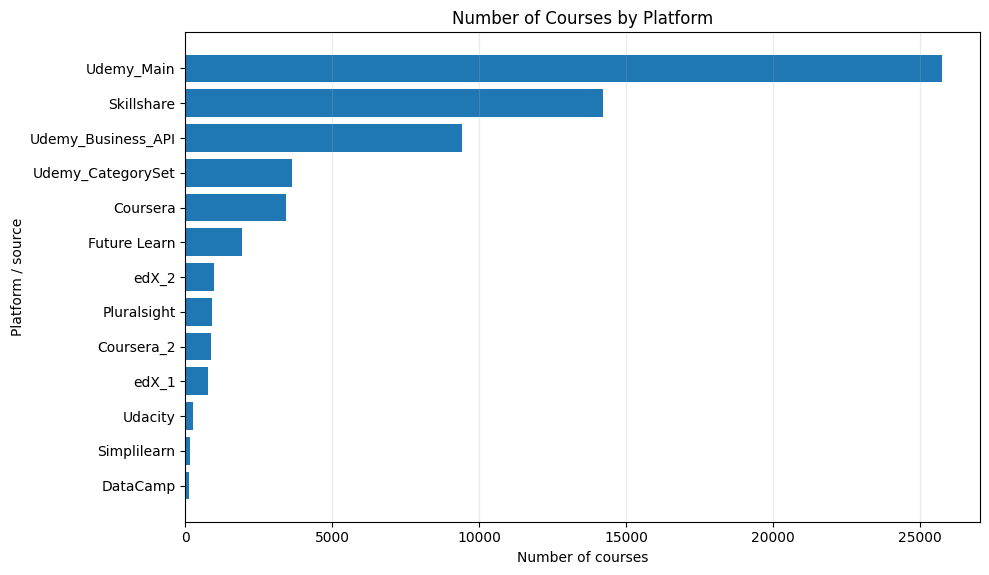

In [ ]:
# -------------------------- 4. Reviews and data coverage --------------------------
def course_key(value):
    if pd.isna(value): return ''
    raw = str(value).strip().lower()
    m = re.search(r'(?:learn|specializations)/([^/?#]+)',raw)
    if m: return m.group(1)
    parsed = urlparse(raw if '://' in raw else '')
    if parsed.path:
        parts = [x for x in parsed.path.split('/') if x]
        if parts: return parts[-1]
    return raw.strip('/')
joined_reviews = pd.DataFrame(columns=['course_id','course_title','source','Review','review_label'])
reviews = read_csv_safe('reviews_by_course.csv')
if reviews is not None:
    text_col = find_col(reviews,['Review','review','review_text','text','content'])
    id_col = find_col(reviews,['CourseId','course_id','course_url','url','course','slug'])
    label_col = find_col(reviews,['Label','label','sentiment','review_rating'])
    if text_col and id_col:
        rw = pd.DataFrame({'review_key':reviews[id_col].apply(course_key),'Review':reviews[text_col].apply(clean_text),
                           'review_label':reviews[label_col] if label_col else np.nan})
        rw = rw[(rw.review_key!='')&(rw.Review!='')]
        catalog = unified[unified['url'].str.contains('coursera',case=False,na=False)].copy()
        catalog['review_key'] = catalog['url'].apply(course_key)
        joined_reviews = rw.merge(catalog[['course_id','course_title','source','review_key']].drop_duplicates('review_key'),on='review_key',how='inner')
        joined_reviews = joined_reviews[['course_id','course_title','source','Review','review_label']]
        print(f'Review rows with text and ID: {len(rw):,}; matched rows: {len(joined_reviews):,}; matched courses: {joined_reviews.course_id.nunique():,}')
        joined_reviews.to_csv(OUTPUT_DIR/'course_reviews_joined.csv',index=False)
    else:
        print('Review join skipped: cannot identify review text and course identifier columns. Columns:',reviews.columns.tolist())
matched_counts = joined_reviews.groupby('course_id').size().rename('matched_review_text_count')
unified = unified.merge(matched_counts,left_on='course_id',right_index=True,how='left')
unified['matched_review_text_count'] = unified['matched_review_text_count'].fillna(0).astype(int)
unified['num_reviews_best'] = unified['num_reviews'].fillna(unified['matched_review_text_count'].where(unified['matched_review_text_count']>0))
coverage = unified.groupby('source').agg(total_courses=('course_id','count'),courses_with_rating=('rating','count'),
    courses_with_review_count=('num_reviews','count'),courses_with_students=('students','count'),courses_with_price=('price','count'),
    courses_with_written_reviews=('matched_review_text_count',lambda s:int((s>0).sum()))).reset_index()
for c,new in [('courses_with_rating','rating_coverage_pct'),('courses_with_review_count','review_count_coverage_pct'),('courses_with_students','students_coverage_pct'),('courses_with_price','price_coverage_pct')]:
    coverage[new] = (100*coverage[c]/coverage.total_courses).round(1)
print('Coverage by source (shown here; not exported to CSV):')
display(coverage.sort_values('total_courses',ascending=False).reset_index(drop=True))

# Chart 1: catalogue size by platform
plot_cov=coverage.sort_values('total_courses',ascending=True)
fig, ax = plt.subplots(figsize=(10, max(4, 0.45*len(plot_cov))))
ax.barh(plot_cov['source'], plot_cov['total_courses'])
ax.set_title('Number of Courses by Platform')
ax.set_xlabel('Number of courses')
ax.set_ylabel('Platform / source')
ax.grid(axis='x', alpha=.25)
plt.tight_layout()
plt.show()



## Conservative English filter

### Language filtering

**Purpose:** This is a conservative text-language filter. Review the rows it removes: language detection can make mistakes, especially for short titles or course names containing technical terms.



In [ ]:
# --------------------------  English filter --------------------------
try:
    from langdetect import detect_langs, DetectorFactory
    DetectorFactory.seed = 0
    HAS_LANGDETECT = True
except ImportError:
    HAS_LANGDETECT = False
    print('langdetect unavailable; using script-based filtering only. Install with: pip install langdetect')
FOREIGN_SCRIPT = re.compile(r'[\u0400-\u04ff\u0590-\u05ff\u0600-\u06ff\u0900-\u097f\u0e00-\u0e7f\u3040-\u30ff\u3400-\u4dbf\u4e00-\u9fff\uac00-\ud7af]')
FOREIGN_WORDS = {'de','del','la','el','los','las','para','con','y','und','der','mit','für','fur','les','des','pour','avec','il','che','em','uma','da','dos','um','como','curso','aprende','aprenda','completo','einführung','einfuhrung','cours','nel','della','och','een','voor','introducción','introduccion','fundamentos','aprender','invertir','practicando','lernen','einsteiger','una','uno'}
WORD_RE = re.compile(r"[a-zA-ZÀ-ÿ']+")
def is_english_course(title, description=''):
    title = '' if pd.isna(title) else str(title)
    desc = '' if pd.isna(description) else str(description)[:400]
    # Do not reject merely because a course teaches a foreign language; only reject foreign script in title.
    if FOREIGN_SCRIPT.search(title): return False
    words = [w.lower() for w in WORD_RE.findall(title)]
    hits = sum(w in FOREIGN_WORDS for w in words)
    if hits >= 2 or (hits >= 1 and len(words)<=3): return False
    if HAS_LANGDETECT and len(title+' '+desc)>=35:
        try:
            pred = detect_langs((title+'. '+desc).strip())[0]
            if pred.lang != 'en' and pred.prob >= 0.92: return False
        except Exception: pass
    return True
mask = unified.apply(lambda r:is_english_course(r.course_title,r.description),axis=1)
removed = unified.loc[~mask]
lang_report = unified.assign(removed=~mask).groupby('source').agg(total=('course_id','count'),removed=('removed','sum')).reset_index()
lang_report['removed_pct']=(100*lang_report.removed/lang_report.total).round(2)
lang_report.to_csv(OUTPUT_DIR/'language_filter_report.csv',index=False)
print(f'Language filter removed {len(removed):,} of {len(unified):,} courses. Inspect outputs/language_filter_report.csv and review removed titles.')
removed[['source','course_title']].head(100).to_csv(OUTPUT_DIR/'removed_language_samples.csv',index=False)
unified = unified.loc[mask].copy().reset_index(drop=True)
unified['course_id'] = [f'C{i:06d}' for i in range(len(unified))]
unified['combined_text'] = (unified['course_title']+' . '+unified['description']+' . '+unified['category']+' . '+unified['level']).str.strip()
unified.to_csv(OUTPUT_DIR/'unified_courses_english.csv',index=False)
print(f'English-filtered catalogue: {len(unified):,} courses from {unified.source.nunique()} sources')


Language filter removed 1,081 of 62,457 courses. Inspect outputs/language_filter_report.csv and review removed titles.
English-filtered catalogue: 61,376 courses from 13 sources


## 6. Build aligned TF-IDF model

### TF-IDF representation



In [ ]:
# -------------------------- Build aligned TF-IDF model --------------------------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
courses = unified.copy().reset_index(drop=True)
courses['combined_text'] = courses['combined_text'].fillna('').astype(str)
courses['text'] = (courses['course_title'].fillna('').astype(str)+'. '+courses['description'].fillna('').astype(str).str.slice(0,300)).str.strip()
courses['title_norm'] = courses['course_title'].fillna('').str.lower().str.replace(r'[^a-z0-9 ]','',regex=True).str.strip()
vectorizer = TfidfVectorizer(max_features=25000,stop_words='english',ngram_range=(1,2),min_df=1)
tfidf_matrix = vectorizer.fit_transform(courses['combined_text'])
id_to_idx = dict(zip(courses.course_id,courses.index))
print(f'TF-IDF ready: {tfidf_matrix.shape[0]:,} courses x {tfidf_matrix.shape[1]:,} terms')


TF-IDF ready: 61,376 courses x 25,000 terms



Keyword recommenders

### Keyword recommendation methods




In [ ]:
# TF-IDF + cosine similarity
# Method 1: TF-IDF converts course text into numerical features.
# Method 2: cosine similarity compares these numerical features to find similar courses.

DISPLAY_COLS = ['course_id','course_title','source','category','level','rating','num_reviews_best','students','price','url']

def search_course(query, top_n=10):
    """Find course titles containing the search phrase."""
    mask = courses['course_title'].fillna('').str.contains(re.escape(query), case=False, na=False)
    return courses.loc[mask, DISPLAY_COLS].head(top_n).reset_index(drop=True)

def recommend_similar(course_id, top_n=10, same_source_only=False):
    """Recommend courses using TF-IDF vectors and cosine similarity."""
    if course_id not in id_to_idx:
        raise ValueError(f'Unknown course_id {course_id!r}. Search for a course first.')
    idx = id_to_idx[course_id]
    scores = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).ravel()
    result = courses.copy()
    result['similarity_score'] = scores
    result = result[result['course_id'] != course_id]
    if same_source_only:
        result = result[result['source'] == courses.loc[idx, 'source']]
    cols = ['course_id','course_title','source','category','level','rating','num_reviews_best','students','similarity_score','url']
    return result.sort_values('similarity_score', ascending=False).head(top_n)[cols].reset_index(drop=True)

print('Ready: TF-IDF + cosine similarity')
print('TF-IDF matrix shape:', tfidf_matrix.shape)


Ready: TF-IDF + cosine similarity
TF-IDF matrix shape: (61376, 25000)


##  Hybrid recommendation: combine text similarity and course rating




In [ ]:
# -------------------------- Hybrid recommender --------------------------


courses["rating_numeric"] = pd.to_numeric(courses["rating"], errors="coerce")

rating_min = courses["rating_numeric"].min()
rating_max = courses["rating_numeric"].max()

if pd.notna(rating_min) and pd.notna(rating_max) and rating_max > rating_min:
    courses["rating_norm"] = (
        (courses["rating_numeric"] - rating_min) / (rating_max - rating_min)
    )
elif pd.notna(rating_min) and pd.notna(rating_max):

    courses["rating_norm"] = np.nan
else:
    courses["rating_norm"] = np.nan

def recommend_hybrid(course_id, top_n=10, same_source_only=False,
                     text_weight=0.7, rating_weight=0.3):

    if course_id not in id_to_idx:
        raise ValueError(f'Unknown course_id {course_id!r}. Search for a course first.')

    if not np.isclose(text_weight + rating_weight, 1.0):
        raise ValueError("text_weight + rating_weight must equal 1.0.")
    if text_weight < 0 or rating_weight < 0:
        raise ValueError("Weights must be non-negative.")

    idx = id_to_idx[course_id]
    scores = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).ravel()

    result = courses.copy()
    result["text_similarity"] = scores
    has_rating = result["rating_norm"].notna()

    result["hybrid_score"] = result["text_similarity"]
    result.loc[has_rating, "hybrid_score"] = (
        text_weight * result.loc[has_rating, "text_similarity"]
        + rating_weight * result.loc[has_rating, "rating_norm"]
    )


    result = result[result["course_id"] != course_id]

    if same_source_only:
        result = result[result["source"] == courses.loc[idx, "source"]]

    cols = [
        "course_id", "course_title", "source", "category", "level",
        "rating", "num_reviews_best", "students", "text_similarity",
        "rating_norm", "hybrid_score", "url"
    ]
    return result.sort_values(
        "hybrid_score", ascending=False
    ).head(top_n)[cols].reset_index(drop=True)

print("Hybrid recommender ready.")
print("Default weights: 70% text similarity and 30% normalized rating.")


Hybrid recommender ready.
Default weights: 70% text similarity and 30% normalized rating.


## 8. EDA: understand the dataset


In [ ]:
# Basic dataset overview
print('Number of courses:', len(courses))
print('Number of columns:', len(courses.columns))
display(courses.head())
print('Column data types:')
display(courses.dtypes.astype(str).rename('data_type').to_frame())

eda_columns = [c for c in ['course_title','description','category','level','rating','num_reviews_best','students','price'] if c in courses.columns]
missing_summary = courses[eda_columns].isna().sum().to_frame('missing_count')
missing_summary['missing_percent'] = (100 * missing_summary['missing_count'] / max(1, len(courses))).round(2)
print('Missing values:')
display(missing_summary)
print('Exact duplicate rows:', int(courses.duplicated().sum()))


Number of courses: 61376
Number of columns: 20


,course_id,course_title,description,category,level,rating,num_reviews,students,price,duration,url,source,title_norm,url_norm,combined_text,matched_review_text_count,num_reviews_best,text,rating_numeric,rating_norm
0,C000000,Bitcoin or How I Learned to Stop Worrying and ...,,Business Finance,All Levels,NaN,936.0,65576.0,0.0,8.0,https://www.udemy.com/bitcoin-or-how-i-learned...,Udemy_CategorySet,bitcoin or how i learned to stop worrying and ...,https://www.udemy.com/bitcoin-or-how-i-learned...,Bitcoin or How I Learned to Stop Worrying and ...,0,936.0,Bitcoin or How I Learned to Stop Worrying and ...,NaN,NaN
1,C000001,Accounting in 60 Minutes - A Brief Introduction,,Business Finance,Beginner Level,NaN,4397.0,56659.0,0.0,1.5,https://www.udemy.com/accounting-in-60-minutes...,Udemy_CategorySet,accounting in 60 minutes a brief introduction,https://www.udemy.com/accounting-in-60-minutes...,Accounting in 60 Minutes - A Brief Introductio...,0,4397.0,Accounting in 60 Minutes - A Brief Introduction.,NaN,NaN
2,C000002,Stock Market Investing for Beginners,,Business Finance,All Levels,NaN,2698.0,50855.0,0.0,1.5,https://www.udemy.com/the-beginners-guide-to-t...,Udemy_CategorySet,stock market investing for beginners,https://www.udemy.com/the-beginners-guide-to-t...,Stock Market Investing for Beginners . . Busi...,0,2698.0,Stock Market Investing for Beginners.,NaN,NaN
3,C000003,Introduction to Financial Modeling,,Business Finance,All Levels,NaN,1463.0,29167.0,0.0,1.5,https://www.udemy.com/financial-modeling-asimp...,Udemy_CategorySet,introduction to financial modeling,https://www.udemy.com/financial-modeling-asimp...,Introduction to Financial Modeling . . Busine...,0,1463.0,Introduction to Financial Modeling.,NaN,NaN
4,C000004,The Complete Financial Analyst Course 2017,,Business Finance,All Levels,NaN,2347.0,24481.0,195.0,10.0,https://www.udemy.com/the-complete-financial-a...,Udemy_CategorySet,the complete financial analyst course 2017,https://www.udemy.com/the-complete-financial-a...,The Complete Financial Analyst Course 2017 . ...,0,2347.0,The Complete Financial Analyst Course 2017.,NaN,NaN


Column data types:


,data_type
course_id,object
course_title,object
description,object
category,object
level,object
rating,float64
num_reviews,float64
students,float64
price,float64
duration,object


Missing values:


,missing_count,missing_percent
course_title,0,0.00
description,0,0.00
category,0,0.00
level,0,0.00
rating,22180,36.14
num_reviews_best,21216,34.57
students,33119,53.96
price,47893,78.03


Exact duplicate rows: 0


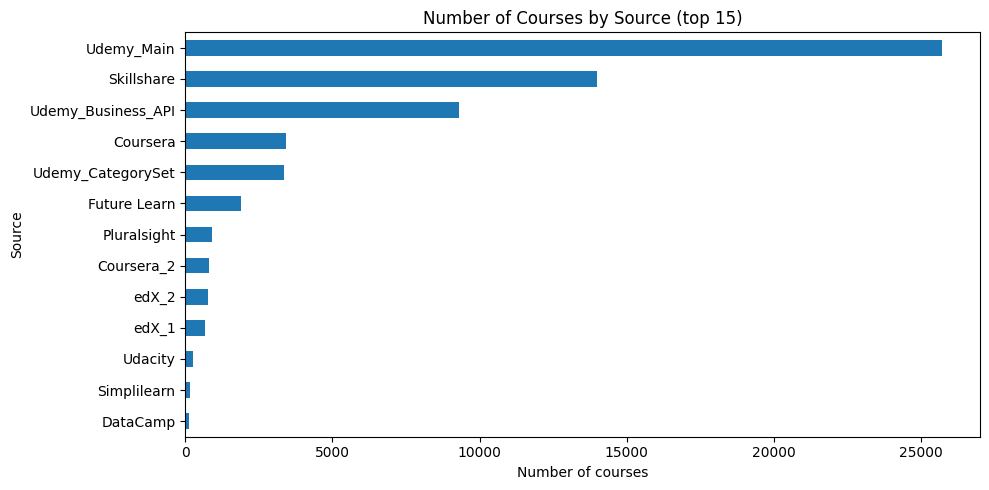

/tmp/ipykernel_55770/1435848885.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(engagement['source'], rotation=35, ha='right')


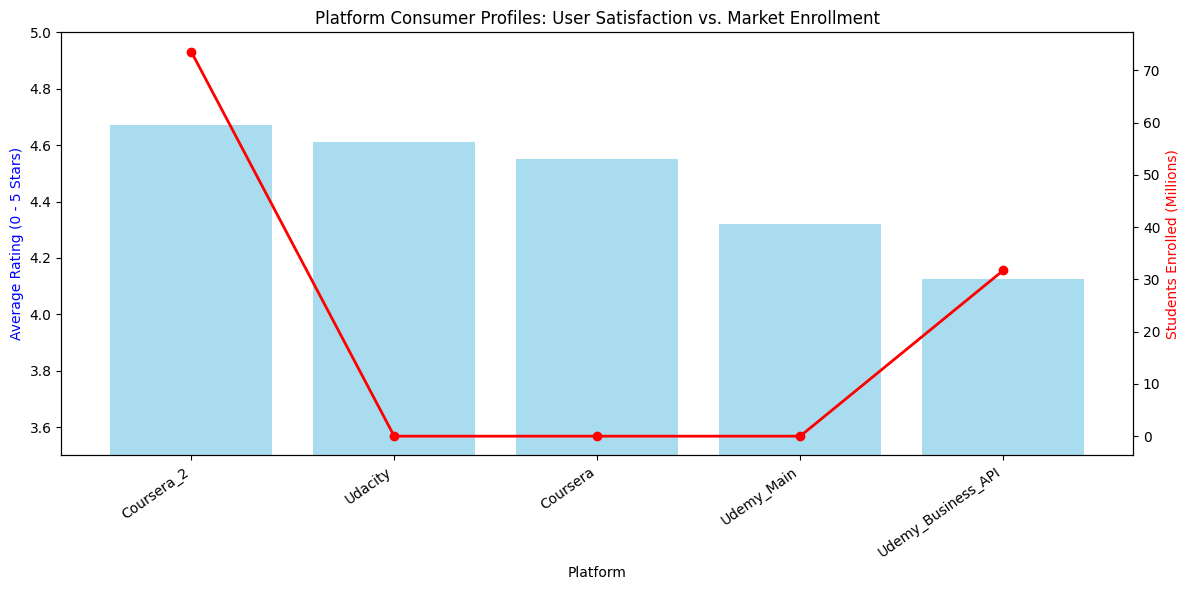

In [ ]:
# EDA graph 1: number of courses per source/platform
source_counts = courses['source'].fillna('Unknown').value_counts().head(15)
plt.figure(figsize=(10,5))
source_counts.sort_values().plot(kind='barh')
plt.title('Number of Courses by Source (top 15)')
plt.xlabel('Number of courses')
plt.ylabel('Source')
plt.tight_layout()
plt.show()

import seaborn as sns
engagement = courses.groupby('source').agg(
    avg_rating=('rating', 'mean'),
    total_students=('students', 'sum')
).reset_index().dropna()

engagement = engagement.sort_values('avg_rating', ascending=False)

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(engagement['source'], engagement['avg_rating'], color='skyblue', alpha=0.7, label='Avg Rating')
ax1.set_ylabel('Average Rating (0 - 5 Stars)', color='blue')
ax1.set_ylim(3.5, 5.0)
ax1.set_xlabel('Platform')

ax2 = ax1.twinx()
ax2.plot(engagement['source'], engagement['total_students'] / 1_000_000, color='red', marker='o', linewidth=2, label='Total Enrolled (Millions)')
ax2.set_ylabel('Students Enrolled (Millions)', color='red')

plt.title('Platform Consumer Profiles: User Satisfaction vs. Market Enrollment')
ax1.set_xticklabels(engagement['source'], rotation=35, ha='right')
fig.tight_layout()
plt.show()


In [ ]:
# Numeric summaries: mean, median, mode, variance, standard deviation, and IQR
numeric_cols = [c for c in ['rating','num_reviews_best','students','price'] if c in courses.columns]
summary_rows = []
for col in numeric_cols:
    values = pd.to_numeric(courses[col], errors='coerce').dropna()
    if values.empty:
        continue
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    summary_rows.append({
        'column': col, 'count': len(values), 'mean': values.mean(),
        'median': values.median(), 'mode': values.mode().iloc[0] if not values.mode().empty else np.nan,
        'variance': values.var(), 'std_dev': values.std(), 'Q1': q1, 'Q3': q3,
        'IQR': iqr, 'lower_fence': lower_fence, 'upper_fence': upper_fence,
        'outlier_count': int(((values < lower_fence) | (values > upper_fence)).sum())
    })
summary_df = pd.DataFrame(summary_rows).round(3)
display(summary_df)



,column,count,mean,median,mode,variance,std_dev,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count
0,rating,39196,4.301,4.4,4.6,1.950000e-01,0.442,4.1,4.6,0.5,3.35,5.35,1456
1,num_reviews_best,40160,1104.095,129.0,3.0,4.291249e+07,6550.763,34.0,549.0,515.0,-738.50,1321.50,5236
2,students,28257,7465.814,1046.0,0.0,3.047994e+09,55208.638,387.0,3138.0,2751.0,-3739.50,7264.50,3824
3,price,13483,3349.933,1920.0,8640.0,1.152230e+07,3394.452,100.0,6400.0,6300.0,-9350.00,15850.00,0


## Evaluation: Precision, Recall and F1-score

In [ ]:
import numpy as np
import pandas as pd

def evaluate_recommenders(sample_size=100, top_k=10):
    eval_courses = courses[courses["category"].notna()].copy()
    eval_courses = eval_courses[eval_courses["category"].astype(str).str.strip().ne("")]
    eval_courses = eval_courses.sample(min(sample_size, len(eval_courses)), random_state=42)

    category_labels = courses["category"].fillna("").astype(str).str.strip().str.casefold()
    rows = []

    for method_name, recommender in [
        ("TF-IDF + cosine", recommend_similar),
        ("Hybrid (text + rating)", recommend_hybrid),
    ]:
        precisions, recalls_capped = [], []

        for _, row in eval_courses.iterrows():
            category = str(row["category"]).strip().casefold()
            relevant_ids = set(
                courses.loc[(courses.index != row.name) & (category_labels == category), "course_id"]
            )
            if not relevant_ids:
                continue

            recs = recommender(row["course_id"], top_n=top_k)
            hits = len(set(recs["course_id"]) & relevant_ids)

            precisions.append(hits / top_k)
            recalls_capped.append(hits / min(top_k, len(relevant_ids)))

        p, r = np.mean(precisions), np.mean(recalls_capped)
        f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0

        rows.append({
            "method": method_name,
            "queries_evaluated": len(precisions),
            f"Precision": p,
            f"Recall ": r,
            f"F1_score": f1,
        })

    results = pd.DataFrame(rows)
    display(results.round(4))
    return results

comparison_results = evaluate_recommenders(sample_size=100, top_k=10)

,method,queries_evaluated,Precision,Recall,F1_score
0,TF-IDF + cosine,96,0.9260,0.9288,0.9274
1,Hybrid (text + rating),96,0.9208,0.9208,0.9208


In [ ]:

from datetime import datetime, timezone
import time

def check_course_links(limit=20, timeout_seconds=8, pause_seconds=0.5):
    try:
        import requests
    except ImportError:
        print('Install requests first: %pip install requests')
        return None

    links = courses[['course_title', 'source', 'url']].copy()
    links['url'] = links['url'].fillna('').astype(str).str.strip()
    links = links[links['url'].str.startswith(('http://', 'https://'))].drop_duplicates('url').head(limit)
    if links.empty:
        print('No valid http/https course URLs found in the dataset.')
        return None

    results = []
    checked_at = datetime.now(timezone.utc).isoformat(timespec='seconds')
    headers = {'User-Agent': 'CourseRecommendationStudentProject/1.0 (link availability check)'}
    for _, row in links.iterrows():
        try:
            response = requests.get(row['url'], headers=headers, timeout=timeout_seconds, allow_redirects=True, stream=True)
            status = response.status_code
            final_url = response.url
            response.close()
            message = 'Reachable' if 200 <= status < 400 else 'HTTP response; inspect status'
        except requests.RequestException as exc:
            status, final_url, message = None, '', f'Could not verify: {type(exc).__name__}'
        results.append({
            'course_title': row['course_title'], 'source': row['source'],
            'url': row['url'], 'http_status': status, 'result': message,
            'final_url': final_url, 'checked_at_utc': checked_at
        })
        time.sleep(pause_seconds)
    link_report = pd.DataFrame(results)
    display(link_report)
    print('This checks link reachability only; it does not confirm course quality, current price, or enrolment availability.')
    return link_report

live_link_report = check_course_links(limit=20)


,course_title,source,url,http_status,result,final_url,checked_at_utc
0,Bitcoin or How I Learned to Stop Worrying and ...,Udemy_CategorySet,https://www.udemy.com/bitcoin-or-how-i-learned...,403,HTTP response; inspect status,https://www.udemy.com/bitcoin-or-how-i-learned...,2026-10-29T09:23:14+00:00
1,Accounting in 60 Minutes - A Brief Introduction,Udemy_CategorySet,https://www.udemy.com/accounting-in-60-minutes...,403,HTTP response; inspect status,https://www.udemy.com/accounting-in-60-minutes...,2026-10-29T09:23:14+00:00
2,Stock Market Investing for Beginners,Udemy_CategorySet,https://www.udemy.com/the-beginners-guide-to-t...,403,HTTP response; inspect status,https://www.udemy.com/the-beginners-guide-to-t...,2026-10-29T09:23:14+00:00
3,Introduction to Financial Modeling,Udemy_CategorySet,https://www.udemy.com/financial-modeling-asimp...,403,HTTP response; inspect status,https://www.udemy.com/financial-modeling-asimp...,2026-10-29T09:23:14+00:00
4,The Complete Financial Analyst Course 2017,Udemy_CategorySet,https://www.udemy.com/the-complete-financial-a...,403,HTTP response; inspect status,https://www.udemy.com/the-complete-financial-a...,2026-10-29T09:23:14+00:00
5,Forex Basics,Udemy_CategorySet,https://www.udemy.com/forex-basics/,403,HTTP response; inspect status,https://www.udemy.com/forex-basics/,2026-10-29T09:23:14+00:00
6,Beginner to Pro in Excel: Financial Modeling a...,Udemy_CategorySet,https://www.udemy.com/beginner-to-pro-in-excel...,403,HTTP response; inspect status,https://www.udemy.com/beginner-to-pro-in-excel...,2026-10-29T09:23:14+00:00
7,Black Algo Trading: Build Your Trading Robot,Udemy_CategorySet,https://www.udemy.com/build-your-trading-robot/,403,HTTP response; inspect status,https://www.udemy.com/build-your-trading-robot/,2026-10-29T09:23:14+00:00
8,Financial Analysis: A Recipe for Success,Udemy_CategorySet,https://www.udemy.com/financial-analysis-a-rec...,403,HTTP response; inspect status,https://www.udemy.com/financial-analysis-a-rec...,2026-10-29T09:23:14+00:00
9,Stock Market Foundations,Udemy_CategorySet,https://www.udemy.com/how-to-invest-in-the-sto...,403,HTTP response; inspect status,https://www.udemy.com/how-to-invest-in-the-sto...,2026-10-29T09:23:14+00:00


This checks link reachability only; it does not confirm course quality, current price, or enrolment availability.


## Recommendation demo

Use a keyword to find a course, then choose its course ID to recommend similar courses. The similarity score is a numerical measure of text similarity, not a probability that the learner will like the course.

In [ ]:
# -------------------------- Try both recommenders --------------------------

query = "python"
hits = search_course(query, top_n=10)
display(hits)

if not hits.empty:
    selected_course_id = hits.iloc[0]["course_id"]
    print("Selected course:", hits.iloc[0]["course_title"])

    print("\nBaseline: TF-IDF + cosine similarity")
    display(recommend_similar(selected_course_id, top_n=10))

    print("\nHybrid: text similarity + course rating")
    display(recommend_hybrid(selected_course_id, top_n=10))
else:
    print("No course title matched. Try another search term, such as data science or web development.")


,course_id,course_title,source,category,level,rating,num_reviews_best,students,price,url
0,C000110,Python for Finance: Investment Fundamentals & ...,Udemy_CategorySet,Business Finance,All Levels,NaN,278.0,3811.0,195.0,https://www.udemy.com/python-for-finance-inves...
1,C000384,Python Algo Stock Trading: Automate Your Trading!,Udemy_CategorySet,Business Finance,Beginner Level,NaN,21.0,1165.0,95.0,https://www.udemy.com/algorithmic-stock-tradin...
2,C000519,Python for Trading & Investing,Udemy_CategorySet,Business Finance,All Levels,NaN,25.0,638.0,95.0,https://www.udemy.com/python-for-trading-inves...
3,C000578,Python Algo Trading: FX Trading with Oanda,Udemy_CategorySet,Business Finance,All Levels,NaN,42.0,453.0,200.0,https://www.udemy.com/python-algo-trading-fx-t...
4,C000587,Stock Technical Analysis with Python,Udemy_CategorySet,Business Finance,Beginner Level,NaN,35.0,409.0,50.0,https://www.udemy.com/stock-technical-analysis...
5,C000633,Python Algo Trading: Sentiment Trading with News,Udemy_CategorySet,Business Finance,All Levels,NaN,19.0,294.0,200.0,https://www.udemy.com/hedge-fund-strategy-trad...
6,C000648,Quantitative Trading Analysis with Python,Udemy_CategorySet,Business Finance,Intermediate Level,NaN,17.0,256.0,50.0,https://www.udemy.com/quantitative-trading-ana...
7,C000677,Investment Portfolio Analysis with Python,Udemy_CategorySet,Business Finance,Beginner Level,NaN,13.0,209.0,50.0,https://www.udemy.com/investment-portfolio-ana...
8,C001256,Learn to code in Python and learn Adobe Photos...,Udemy_CategorySet,Graphic Design,Beginner Level,NaN,1.0,1132.0,50.0,https://www.udemy.com/learn-to-code-in-python-...
9,C002203,Web Programming with Python,Udemy_CategorySet,Subject: Web Development,Beginner Level,NaN,217.0,35267.0,50.0,https://www.udemy.com/web-programming-with-pyt...


Selected course: Python for Finance: Investment Fundamentals & Data Analytics

Baseline: TF-IDF + cosine similarity


,course_id,course_title,source,category,level,rating,num_reviews_best,students,similarity_score,url
0,C029095,Python for Finance: Investment Fundamentals & ...,Udemy_Business_API,Unknown,Unknown,4.52806,17617.0,83072.0,0.806348,/course/python-for-finance-investment-fundamen...
1,C000322,Essentials of Finance and Investment in 2 hours,Udemy_CategorySet,Business Finance,All Levels,NaN,6.0,1403.0,0.589421,https://www.udemy.com/finance-hien-minh-luu/
2,C016693,Python for Finance: Investment Fundamentals & ...,Udemy_Main,Unknown,All Levels,4.60000,26632.0,NaN,0.531897,
3,C000849,How To Crowdfund,Udemy_CategorySet,Business Finance,All Levels,NaN,6.0,43.0,0.465045,https://www.udemy.com/how-to-crowdfund/
4,C001005,Contabilità Generale,Udemy_CategorySet,Business Finance,All Levels,NaN,1.0,4.0,0.465045,https://www.udemy.com/contabilita-generale/
5,C000714,Aprenda a Investir seu Dinheiro,Udemy_CategorySet,Business Finance,All Levels,NaN,28.0,150.0,0.465045,https://www.udemy.com/aprenda-a-investir-seu-d...
6,C000580,Buchführung lernen leicht gemacht,Udemy_CategorySet,Business Finance,All Levels,NaN,39.0,446.0,0.465045,https://www.udemy.com/buchfuehrung-lernen-leic...
7,C000597,Complete Claritas Investment Certificate,Udemy_CategorySet,Business Finance,All Levels,NaN,56.0,388.0,0.445346,https://www.udemy.com/claritas-investment-cert...
8,C000873,Trade Show Samurai,Udemy_CategorySet,Business Finance,All Levels,NaN,7.0,32.0,0.403156,https://www.udemy.com/trade-show-displays/
9,C000962,Easy Finance For Startups,Udemy_CategorySet,Business Finance,All Levels,NaN,4.0,9.0,0.399892,https://www.udemy.com/easy-finance-for-startups/



Hybrid: text similarity + course rating


,course_id,course_title,source,category,level,rating,num_reviews_best,students,text_similarity,rating_norm,hybrid_score,url
0,C029095,Python for Finance: Investment Fundamentals & ...,Udemy_Business_API,Unknown,Unknown,4.52806,17617.0,83072.0,0.806348,0.882015,0.829048,/course/python-for-finance-investment-fundamen...
1,C016693,Python for Finance: Investment Fundamentals & ...,Udemy_Main,Unknown,All Levels,4.60000,26632.0,NaN,0.531897,0.900000,0.642328,
2,C000322,Essentials of Finance and Investment in 2 hours,Udemy_CategorySet,Business Finance,All Levels,NaN,6.0,1403.0,0.589421,NaN,0.589421,https://www.udemy.com/finance-hien-minh-luu/
3,C019262,ChatGPT for Finance and Investment Professionals,Udemy_Main,Unknown,All Levels,4.80000,32.0,NaN,0.317189,0.950000,0.507033,
4,C017667,Python Finance: Stock Analysis & Data Fundamen...,Udemy_Main,Unknown,Beginner,4.20000,157.0,NaN,0.372156,0.800000,0.500509,
5,C015519,"Google Data Studio For Data Analytics, Busines...",Udemy_Main,Unknown,All Levels,4.50000,209.0,NaN,0.313968,0.875000,0.482277,
6,C035890,"Google Data Studio For Data Analytics, Busines...",Udemy_Business_API,Unknown,Unknown,4.52816,13.0,152.0,0.296428,0.882040,0.472112,/course/google-data-studio-for-data-analytics-...
7,C000849,How To Crowdfund,Udemy_CategorySet,Business Finance,All Levels,NaN,6.0,43.0,0.465045,NaN,0.465045,https://www.udemy.com/how-to-crowdfund/
8,C000580,Buchführung lernen leicht gemacht,Udemy_CategorySet,Business Finance,All Levels,NaN,39.0,446.0,0.465045,NaN,0.465045,https://www.udemy.com/buchfuehrung-lernen-leic...
9,C001005,Contabilità Generale,Udemy_CategorySet,Business Finance,All Levels,NaN,1.0,4.0,0.465045,NaN,0.465045,https://www.udemy.com/contabilita-generale/
